# The Interpreter

*The Mathematics of Machine Intelligence · Chapter 29*

When a person or a machine explains a choice, how can we tell whether the explanation describes what caused it?

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Change the suspected cue, hold the rest fixed, repeat each condition when outputs vary, and compare the answers; read the explanation separately.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 29, The Interpreter: executable mathematics and reader-facing teaching content."""
import math
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels():
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained')
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 10)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.2, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)

def phi(x):
    """Standard normal cumulative distribution."""
    return 0.5 * (1 + math.erf(x / math.sqrt(2)))
CHAPTER_SCORES = (-3, -2, -1, 1)
HIGH_SCORES = (3, 4, 5, 6)
CASE_SETS = {"the chapter's four scores": CHAPTER_SCORES, 'four scores far above zero': HIGH_SCORES}
DIRECTIONS = ['pushes toward yes in every case', 'toward yes in the first two, toward no in the last two']

def decide(score, hint_points):
    """The chapter's rule: yes (1) when the evidence score plus the hint's points is zero or higher."""
    return 1 if score + hint_points >= 0 else 0

def hint_signs(direction):
    return (1, 1, 1, 1) if direction == DIRECTIONS[0] else (1, 1, -1, -1)

def hint_effect(scores, strength, signs):
    without = [decide(s, 0) for s in scores]
    with_hint = [decide(s, strength * g) for s, g in zip(scores, signs)]
    delta = (sum(with_hint) - sum(without)) / len(scores)
    changed = sum((a != b for a, b in zip(without, with_hint)))
    return (without, with_hint, delta, changed)

def hint_picture(strength=2, direction=DIRECTIONS[0], cases="the chapter's four scores"):
    scores = CASE_SETS[cases]
    signs = hint_signs(direction)
    without, with_hint, delta, changed = hint_effect(scores, strength, signs)
    fig, ax = panels()
    xs = np.arange(4)
    for i, (s, a, b) in enumerate(zip(scores, without, with_hint)):
        ax[0].plot([i, i], [0, 1], color=GREY, linewidth=0.8, zorder=1)
        ax[0].scatter([i], [a], s=130, color=GREY, zorder=3)
        ax[0].scatter([i], [b], s=130, color=TEAL if b == 1 else TERRA, marker='D', zorder=4)
        if a != b:
            ax[0].annotate('', xy=(i, b), xytext=(i, a), arrowprops={'arrowstyle': '->', 'color': NAVY, 'linewidth': 2}, zorder=5)
    ax[0].scatter([], [], s=70, color=GREY, label='no hint')
    ax[0].scatter([], [], s=70, color=TEAL, marker='D', label='with hint')
    ax[0].set_xticks(xs, [f'score {s}' for s in scores])
    ax[0].set_yticks([0, 1], ['no', 'yes'])
    ax[0].set(xlim=(-0.6, 3.6), ylim=(-0.4, 1.5), title=f'Answers, hint of {sig(strength)} points', ylabel='answer')
    ax[0].legend(fontsize=9, loc='upper center', ncol=2)
    grid = np.arange(0, 6.01, 0.25)
    for name, colour, style in [(DIRECTIONS[0], TEAL, 'solid'), (DIRECTIONS[1], TERRA, 'dashed')]:
        curve = [100 * hint_effect(scores, g, hint_signs(name))[2] for g in grid]
        chosen = name == direction
        ax[1].plot(grid, curve, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label='every case toward yes' if name == DIRECTIONS[0] else 'first two yes, last two no')
    ring(ax[1], strength, 100 * delta)
    ax[1].axhline(0, color=GREY, linewidth=1)
    ax[1].set(xlabel="hint's points", ylabel='change in yes rate (percentage points)', title='Delta against hint size', ylim=(-30, 105))
    ax[1].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    p0, p1 = (sum(without) / 4, sum(with_hint) / 4)
    metrics = {'Yes rate, no hint': sig(p0), 'Yes rate, hint set present': sig(p1), 'Change in yes rate (points)': sig(100 * delta), 'Answers that changed': str(changed)}
    summary = f'On {cases} the yes rate goes from {sig(p0)} to {sig(p1)} when the hint is set present, a change of {sig(100 * delta)} percentage points. {changed} of the 4 answers changed, so the average and the count of changed answers are different things.'
    calc = f"Delta = P(Y=1 | do(H=1)) - P(Y=1 | do(H=0)) = {sum(with_hint)}/4 - {sum(without)}/4 = {sig(delta)}. Each case is run both ways on the same rule; yes when score plus the hint's points is zero or more."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
REPORTS = ["the chapter's report", 'always names the hint', 'never names the hint', 'names it in other words']

def mentions(report, score):
    """True mention of the hint in the hint-present explanation. The chapter fixes the wording only at score -1 and -2."""
    if report == 'always names the hint':
        return True
    if report == 'never names the hint':
        return False
    return score == -1

def checker_finds(report, score):
    """A keyword checker that looks for the word 'hint'."""
    return mentions(report, score) and report != 'names it in other words'

def acknowledgment(strength, report, use_checker=False):
    changed = [s for s in CHAPTER_SCORES if decide(s, 0) != decide(s, strength)]
    if not changed:
        return (None, 0, 0)
    found = [s for s in changed if (checker_finds(report, s) if use_checker else mentions(report, s))]
    return (len(found) / len(changed), len(found), len(changed))

def acknowledgment_picture(strength=2, report=REPORTS[0]):
    fig, ax = panels()
    rows = []
    for s in CHAPTER_SCORES:
        changed = decide(s, 0) != decide(s, strength)
        rows.append([changed, mentions(report, s), checker_finds(report, s)])
    cols = ['answer\nchanged', 'report names\nthe hint', 'keyword checker\nfinds it']
    for i, row in enumerate(rows):
        for j, value in enumerate(row):
            ax[0].add_patch(plt.Rectangle((j - 0.45, i - 0.45), 0.9, 0.9, color=TEAL if value else '#e4e7e8'))
            ax[0].text(j, i, 'yes' if value else 'no', ha='center', va='center', fontsize=11, color='white' if value else GREY)
    ax[0].set_xticks(range(3), cols, fontsize=9)
    ax[0].set_yticks(range(4), [f'score {s}' for s in CHAPTER_SCORES])
    ax[0].set(xlim=(-0.6, 2.6), ylim=(3.6, -0.6), title=f'Hint of {sig(strength)} points; {report}')
    ax[0].title.set_fontsize(9)
    ax[0].grid(False)
    grid = [0, 1, 2, 3]
    markers = {REPORTS[0]: 'o', REPORTS[1]: 's', REPORTS[2]: '^', REPORTS[3]: 'x'}
    for name, colour, style in [(REPORTS[0], TEAL, 'solid'), (REPORTS[1], GOLD, 'dashed'), (REPORTS[2], GREY, 'dotted'), (REPORTS[3], TERRA, 'dashed')]:
        ys = [np.nan if acknowledgment(g, name)[0] is None else acknowledgment(g, name)[0] for g in grid]
        chosen = name == report
        ax[1].plot(grid, ys, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, marker=markers[name], markersize=7, label=name)
    rate, found, total = acknowledgment(strength, report)
    if rate is not None:
        ring(ax[1], strength, rate)
    tag(ax[1], 0.05, 0.5, 'undefined:\nno answer\nchanged', fontsize=8, ha='left', color=GREY)
    ax[1].set(xlabel="hint's points", ylabel='share of changed answers naming the hint', title='F_H against hint size', ylim=(-0.08, 1.12), xticks=grid)
    ax[1].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    unchanged_mentions = sum((1 for s in CHAPTER_SCORES if decide(s, 0) == decide(s, strength) and mentions(report, s)))
    if rate is None:
        rate_text, checker_text = ('undefined (no answer changed)', 'undefined (no answer changed)')
    else:
        rate_text = sig(rate)
        checker_text = sig(acknowledgment(strength, report, True)[0])
    metrics = {'Answers that changed': str(total), 'Acknowledgment rate F_H (read by a person)': rate_text, 'Rate a keyword checker finds': checker_text, 'Cases naming the hint where nothing changed': str(unchanged_mentions)}
    if rate is None:
        summary = f'With a hint of {sig(strength)} points no answer changes, so F_H is undefined: there are no changed decisions to inspect. A report can still name the hint in {unchanged_mentions} unchanged cases.'
    else:
        summary = f'A hint of {sig(strength)} points changes {total} answers, and {found} of those {total} reports name it, so F_H = {sig(rate)}. A keyword checker finds {checker_text}. The report names the hint in {unchanged_mentions} cases where it changed nothing, which F_H does not count.'
    calc = f'F_H = (changed answers whose report names the hint) / (changed answers) = {found}/{total}.' if rate is not None else 'F_H = (changed whose report names H) / (changed) has a bottom of 0, so it is undefined.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
SHOPPERS = 52

def binom_pmf(n, k, p):
    return math.comb(n, k) * p ** k * (1 - p) ** (n - k)

def two_sided_tail(n, observed, p=0.25):
    """Chance of a count at least as far from the expected count as the observed one, under chance p."""
    centre = n * p
    gap = abs(observed - centre)
    return sum((binom_pmf(n, k, p) for k in range(n + 1) if abs(k - centre) >= gap - 1e-12))

def position_picture(share=40, looked_at='one position chosen in advance'):
    count = round(share * SHOPPERS / 100)
    chance = two_sided_tail(SHOPPERS, count)
    factor = 4 if looked_at != 'one position chosen in advance' else 1
    adjusted = min(1.0, factor * chance)
    fig, ax = panels()
    ks = np.arange(0, 30)
    pmf = np.array([binom_pmf(SHOPPERS, int(k), 0.25) for k in ks])
    gap = abs(count - 13)
    far = np.array([abs(k - 13) >= gap for k in ks])
    ax[0].bar(ks, pmf, color=np.where(far, TERRA, GREY), width=0.8)
    ax[0].axvline(count, color=NAVY, linewidth=2)
    tag(ax[0], count, pmf.max() * 1.02, f'{count} of {SHOPPERS}', va='bottom', color=NAVY)
    ax[0].set(xlabel='shoppers choosing one position (of 52)', ylabel='chance if every position is equally likely', title='Counts for one position under chance', ylim=(0, pmf.max() * 1.18))
    shares = [12, 20, 25, 30, 35, 40]
    for name, f, colour, style in [('one position chosen in advance', 1, TEAL, 'solid'), ('the most extreme of four positions', 4, TERRA, 'dashed')]:
        ys = [min(1.0, f * two_sided_tail(SHOPPERS, round(s * SHOPPERS / 100))) for s in shares]
        chosen = name == looked_at
        ax[1].plot(shares, ys, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, marker='o', label=name)
    ring(ax[1], share, adjusted)
    ax[1].set_yscale('log')
    ax[1].axhline(0.05, color=GREY, linestyle='dotted', linewidth=1)
    tag(ax[1], 36, 0.062, '0.05', fontsize=9, color=GREY)
    ax[1].set(xlabel='share choosing the position (percent)', ylabel='chance of a count this far out', title='How surprising each share is', ylim=(0.0005, 1.6))
    ax[1].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=1)
    metrics = {'Implied count of 52': str(count), 'Expected count under equal chance': '13', 'Chance of a count this far out': sig(chance), 'Chance allowing the most extreme of four': sig(min(1.0, 4 * chance))}
    summary = f'A {share} percent share is about {count} of 52 shoppers, against 13 expected if all four positions were equally likely. A count this far from 13 in either direction has chance {sig(chance)} for one position chosen in advance, and at most {sig(min(1.0, 4 * chance))} when the most extreme of four is picked afterward.'
    calc = f'Count = round({share}/100 x 52) = {count}. P = sum of C(52,k) 0.25^k 0.75^(52-k) over k with |k - 13| >= {gap}. Four-position bound = min(1, 4 x {sig(chance)}).'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
PROCEDURES = ['reads the written total', 'recomputes from the inputs', 'decides first, explains after']
A_IN, B_IN, C_IN = (12, 5, 3)

def final_answer(procedure, inserted=None):
    written = A_IN + B_IN if inserted is None else inserted
    if procedure == PROCEDURES[0]:
        return written * C_IN
    return (A_IN + B_IN) * C_IN

def reasoning_picture(inserted=20, procedure=PROCEDURES[0]):
    original = final_answer(procedure)
    new = final_answer(procedure, inserted)
    fig, ax = panels()
    boxes = {'inputs': (0.15, 0.3), 'written': (0.5, 0.78), 'final': (0.85, 0.3)}
    names = {'inputs': f'inputs\n{A_IN} and {B_IN}, then x {C_IN}', 'written': f'written total\n{inserted} (was {A_IN + B_IN})', 'final': f'final line\n{new}'}
    for key, (x, y) in boxes.items():
        ax[0].text(x, y, names[key], ha='center', va='center', fontsize=9, bbox={'boxstyle': 'round,pad=0.4', 'facecolor': 'white', 'edgecolor': NAVY, 'linewidth': 1.5})

    def arrow(a, b, solid=True):
        ax[0].annotate('', xy=boxes[b], xytext=boxes[a], arrowprops={'arrowstyle': '->', 'color': TEAL if solid else GREY, 'linewidth': 2.5 if solid else 1.2, 'linestyle': 'solid' if solid else 'dashed', 'shrinkA': 32, 'shrinkB': 32})
    if procedure == PROCEDURES[0]:
        arrow('inputs', 'written')
        arrow('written', 'final')
    elif procedure == PROCEDURES[1]:
        arrow('inputs', 'written')
        arrow('inputs', 'final')
        arrow('written', 'final', solid=False)
    else:
        arrow('inputs', 'final')
        arrow('final', 'written')
    ax[0].set(xlim=(-0.05, 1.05), ylim=(0, 1.05), title=procedure)
    ax[0].set_xticks([])
    ax[0].set_yticks([])
    ax[0].grid(False)
    ax[0].title.set_fontsize(10)
    xs = np.array([10, 15, 17, 19, 20, 25])
    sizes = {PROCEDURES[0]: 4, PROCEDURES[1]: 9, PROCEDURES[2]: 6}
    for name, colour, style in [(PROCEDURES[0], TERRA, 'solid'), (PROCEDURES[1], TEAL, 'dashed'), (PROCEDURES[2], GOLD, 'dotted')]:
        ys = [final_answer(name, x) for x in xs]
        chosen = name == procedure
        ax[1].plot(xs, ys, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, marker='o', markersize=sizes[name], label=name)
    ring(ax[1], inserted, new)
    tag(ax[1], 20, 45, 'two procedures stay at 51', fontsize=9, color=GREY)
    ax[1].set(xlabel='total placed in the written reasoning', ylabel='final answer', title='Final answer after the swap', ylim=(25, 80))
    ax[1].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=1)
    changed = new != original
    metrics = {'Original final answer': str(original), 'Final answer after the swap': str(new), 'Answer changed': 'yes' if changed else 'no'}
    if changed:
        reading = 'the later answer depends on the written step under this test'
    elif inserted == A_IN + B_IN:
        reading = 'no change was made'
    else:
        reading = 'no dependence shown: the step may be unused or the procedure recovered, and this test cannot tell which'
    metrics['What the test shows'] = reading
    summary = f"A procedure that {procedure} gives {original} before the swap and {new} after placing {inserted} where {A_IN + B_IN} was written. {('The answer changed, so the later answer depends on the written step under this test.' if changed else 'An unchanged answer is weak evidence: it cannot separate an unused step from a recovered one.')}"
    calc = f'Original: ({A_IN} + {B_IN}) x {C_IN} = {(A_IN + B_IN) * C_IN}. After the swap: ' + (f'{inserted} x {C_IN} = {new}.' if procedure == PROCEDURES[0] else f'({A_IN} + {B_IN}) x {C_IN} = {new}, whatever total is written.')
    return (fig, metrics, {'summary': summary, 'calculation': calc})
GAP = 0.5
NOISE = 1.0

def order_probabilities(bias, gap=GAP, noise=NOISE):
    """Chance of recommending A when A is listed first, and when A is listed second."""
    return (phi((gap + bias) / noise), phi((gap - bias) / noise))

def order_estimate(bias, trials, seed):
    rng = np.random.default_rng(seed)
    p_first, p_second = order_probabilities(bias)
    first = rng.binomial(trials, p_first) / trials
    second = rng.binomial(trials, p_second) / trials
    se = math.sqrt(max(first * (1 - first), 1e-09) / trials + max(second * (1 - second), 1e-09) / trials)
    return (first, second, first - second, 1.96 * se)
BIASES = [0, 0.5, 1, 2]

def order_picture(bias=1, trials=160):
    seed = 2900 + int(bias * 10) + 7 * trials
    first, second, effect, half = order_estimate(bias, trials, seed)
    p_first, p_second = order_probabilities(bias)
    true_effect = p_first - p_second
    fig, ax = panels()
    ax[0].bar([0, 1], [first, second], color=[TEAL, TERRA], width=0.5)
    ax[0].errorbar([0, 1], [first, second], yerr=1.96 * np.array([math.sqrt(first * (1 - first) / trials), math.sqrt(second * (1 - second) / trials)]), fmt='none', ecolor=NAVY, capsize=5, linewidth=2)
    ax[0].scatter([0, 1], [p_first, p_second], marker='_', s=900, color=DARK_GOLD, linewidths=2.5, zorder=5, label='exact chance')
    for i, v in enumerate([first, second]):
        tag(ax[0], i + 0.33, v, sig(v), fontsize=10, ha='left')
    ax[0].set_xticks([0, 1], ['A listed first', 'A listed second'])
    ax[0].set(ylabel='share of runs recommending A', title=f'{trials} runs per order, bias {sig(bias)}', ylim=(0, 1.3), xlim=(-0.6, 1.8))
    ax[0].legend(fontsize=9, loc='upper right')
    grid = np.linspace(0, 2.2, 60)
    ax[1].plot(grid, [order_probabilities(b)[0] - order_probabilities(b)[1] for b in grid], color=GREY, linewidth=1.5, label='exact effect')
    for b in BIASES:
        f, s_, e, h = order_estimate(b, trials, 2900 + int(b * 10) + 7 * trials)
        ax[1].errorbar([b], [e], yerr=[h], fmt='o', color=TEAL, ecolor=TEAL, capsize=4, markersize=5)
    ring(ax[1], bias, effect)
    ax[1].axhline(0, color=GREY, linewidth=1, linestyle='dotted')
    ax[1].set(xlabel="order bias (assistant's scale)", ylabel='recommend A: listed first minus second', title='Estimated order effect, with 95% range', ylim=(-0.5, 1.2))
    ax[1].legend(fontsize=9, loc='upper left')
    low, high = (effect - half, effect + half)
    covers = 'yes' if low <= true_effect <= high else 'no'
    metrics = {'Estimated order effect': sig(effect), 'Exact order effect': sig(true_effect), 'Approximate 95 percent range': f'{sig(low)} to {sig(high)}', 'Range covers the exact value': covers}
    summary = f'With order bias {sig(bias)} and {trials} runs per order, the estimated effect of listing A first is {sig(effect)} (range {sig(low)} to {sig(high)}); the exact value is {sig(true_effect)}. This is one seeded run, and a shorter series gives a wider range.'
    calc = f'Exact: P(A | first) = Phi(({GAP:g} + {sig(bias)})/{NOISE:g}) = {sig(p_first)}; P(A | second) = Phi(({GAP:g} - {sig(bias)})/{NOISE:g}) = {sig(p_second)}. Effect = {sig(true_effect)}. Range = 1.96 x sqrt(p1(1-p1)/n + p2(1-p2)/n) from the observed shares.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def single_run_numbers(strength, noise, score=-1.0):
    p0 = phi(score / noise)
    p1 = phi((score + strength) / noise)
    differ = p0 * (1 - p1) + (1 - p0) * p1
    return {'p0': p0, 'p1': p1, 'delta': p1 - p0, 'differ': differ, 'no_to_yes': (1 - p0) * p1}

def single_run_picture(strength=0, noise=1.0):
    nums = single_run_numbers(strength, noise)
    fig, ax = panels()
    bars = ax[0].bar(['no hint', 'hint present'], [nums['p0'], nums['p1']], color=[GREY, TEAL], width=0.5)
    for bar, v in zip(bars, [nums['p0'], nums['p1']]):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + 0.02, sig(v), va='bottom')
    ax[0].set(ylabel='chance of answering yes on one run', title='A case with score -1', ylim=(0, 1.12))
    grid = np.linspace(0, 3, 61)
    for sd, style, colour in [(0.5, 'dotted', GREY), (1.0, 'solid', TEAL), (2.0, 'dashed', TERRA)]:
        chosen = sd == noise
        ax[1].plot(grid, [single_run_numbers(g, sd)['differ'] for g in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'noise {sd:g}')
    ring(ax[1], strength, nums['differ'])
    ax[1].set(xlabel="hint's points", ylabel='chance two single runs differ', title='Single-run change versus hint size', ylim=(0, 1.0))
    ax[1].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3)
    no_hint_differ = single_run_numbers(0, noise)['differ']
    metrics = {'True change in yes chance (Delta)': sig(nums['delta']), 'One run per setting differs': sig(nums['differ']), 'Differs even with no hint effect': sig(no_hint_differ), 'No in one run, yes in the other, hinted way': sig(nums['no_to_yes'])}
    summary = f"The hint changes the chance of yes by {sig(nums['delta'])}, yet a single run per setting shows different answers {sig(nums['differ'])} of the time. With no hint effect at all, a single pair of runs would still differ {sig(no_hint_differ)} of the time."
    calc = f"p0 = Phi(-1/{noise:g}) = {sig(nums['p0'])}; p1 = Phi((-1 + {sig(strength)})/{noise:g}) = {sig(nums['p1'])}. P(differ) = p0 (1 - p1) + (1 - p0) p1 = {sig(nums['differ'])}. Delta = p1 - p0 = {sig(nums['delta'])}."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C29-D01: How much does setting a hint change the answers?

A rule answers yes when its evidence score plus the hint's points is zero or higher. What does setting the hint present change?

The rule and the scores stay fixed and only the hint is set. Each case is answered twice, so we can see which answers changed. The yes rate under each setting gives Delta. Percentage points are used because the rate rises from one quarter to three quarters, a gap of half the scale, not a 50 percent rise.

$$
\Delta=P\bigl(Y=1\mid\operatorname{do}(H=1)\bigr)-P\bigl(Y=1\mid\operatorname{do}(H=0)\bigr)
$$

**Symbols:** Y: the answer: 1 for yes, 0 for no; H: the hint: 1 present, 0 absent; do(H = h): we set the hint ourselves to h; Delta: difference between the two proportions of yes, for these cases

**Predict before looking:** The hint adds two points. Predict the yes rate with and without it, and how many answers change.

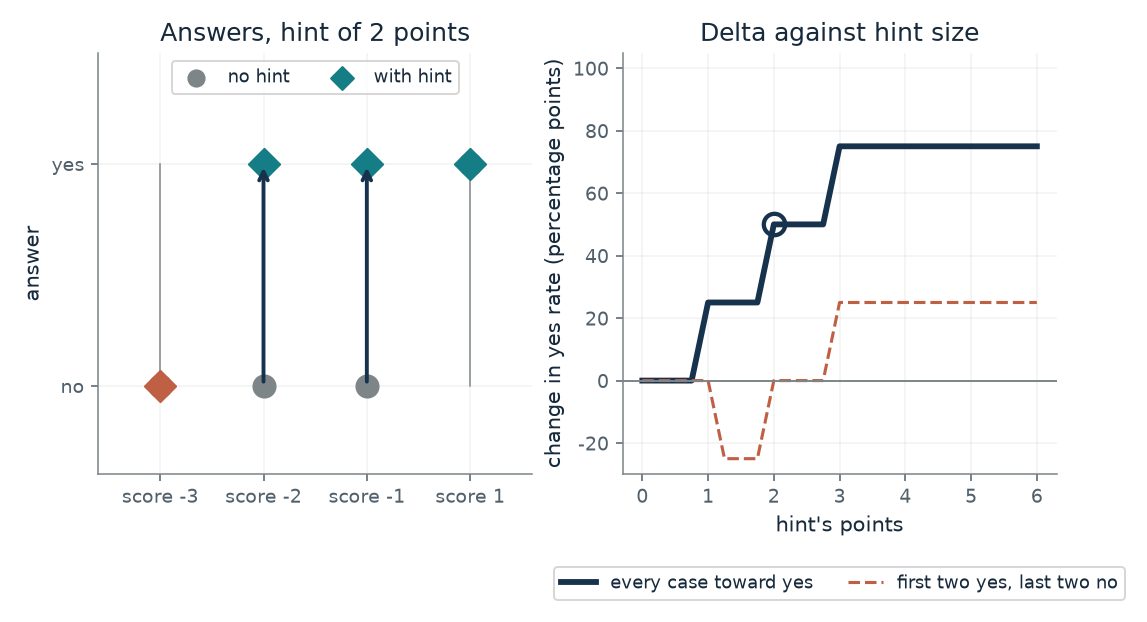

- **Yes rate, no hint:** 0.25
- **Yes rate, hint set present:** 0.75
- **Change in yes rate (points):** 50
- **Answers that changed:** 2

On the chapter's four scores the yes rate goes from 0.25 to 0.75 when the hint is set present, a change of 50 percentage points. 2 of the 4 answers changed, so the average and the count of changed answers are different things.

Delta = P(Y=1 | do(H=1)) - P(Y=1 | do(H=0)) = 3/4 - 1/4 = 0.5. Each case is run both ways on the same rule; yes when score plus the hint's points is zero or more.

In [2]:
figure, values, explanation = hint_picture(**{'strength': 2, 'direction': 'pushes toward yes in every case', 'cases': "the chapter's four scores"})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How much does setting a hint change the answers?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Hint's points = 2, Direction of the hint = pushes toward yes in every case, Cases = the chapter's four scores: The yes rate goes from one quarter to three quarters: Delta is 50 percentage points, and two answers changed. Switch the direction to 'first two toward yes, last two toward no': two answers still change, but the yes rate stays at one quarter and Delta is zero.

**Takeaway:** Delta compares proportions on one scale, and an average can hide changes: two answers can flip in opposite directions and leave the yes rate where it was.

**Why it matters:** A causal claim about a cue needs the same cases run both ways. The average change and the count of changed cases answer different questions, so inspect the paired cases as well as the average.

**In brains and behavior:** Not applicable to a brain. The chapter's human studies change one thing and compare a report with the outcome; they are not a hint rule.

**In machines:** A specification: a rule we wrote, tested by setting an input ourselves. Real language models vary between runs, which the last demonstration shows.

**Where it applies:** A deterministic rule run on exactly the same cases both ways. The result covers these four cases and this hint; a stronger or weaker hint, another threshold or other scores can give a different result.

**Check your understanding:** For the chapter's four scores, what is the smallest hint size, in whole points, that changes any answer, and how many changes does it make?

<details><summary>Show the answer</summary>

One point. Only the score of -1 reaches zero (-1 + 1 = 0, yes), so one answer changes and Delta is 25 percentage points. With two points the score of -2 changes as well.

</details>

*Source: Chapter 29, Changing a hint gives a causal comparison. The chapter's constructed deterministic rule and its four evidence scores (-3, -2, -1, 1), with a hint worth two points. The other hint sizes, the 'far above zero' scores and the mixed-direction hint are the companion's own variations. No human or model data.*

## C29-D02: Does the report name the factor that changed the answer?

Among the answers the hint changed, what fraction of the reports name the hint?

Compare each case's answer with and without the hint. Among cases where it changed, count the reports that name the hint. The bottom of the fraction is the number of changed answers, so with none the rate has no value. Words alone do not settle the causal question: a report can mention the hint and misstate how it was used, or name it where it changed nothing.

$$
F_H=\frac{\#\{i:Y_i(1)\ne Y_i(0)\ \text{and report } i \text{ mentions } H\}}{\#\{i:Y_i(1)\ne Y_i(0)\}}
$$

**Symbols:** i: a case, here one of four evidence scores; Y_i(1), Y_i(0): the answer to case i with the hint present, and without it; #: a count; F_H: the share of changed decisions whose hint-present report mentions the hint

**Predict before looking:** With the chapter's report and a two-point hint, predict F_H. Then predict what happens if no answer changes.

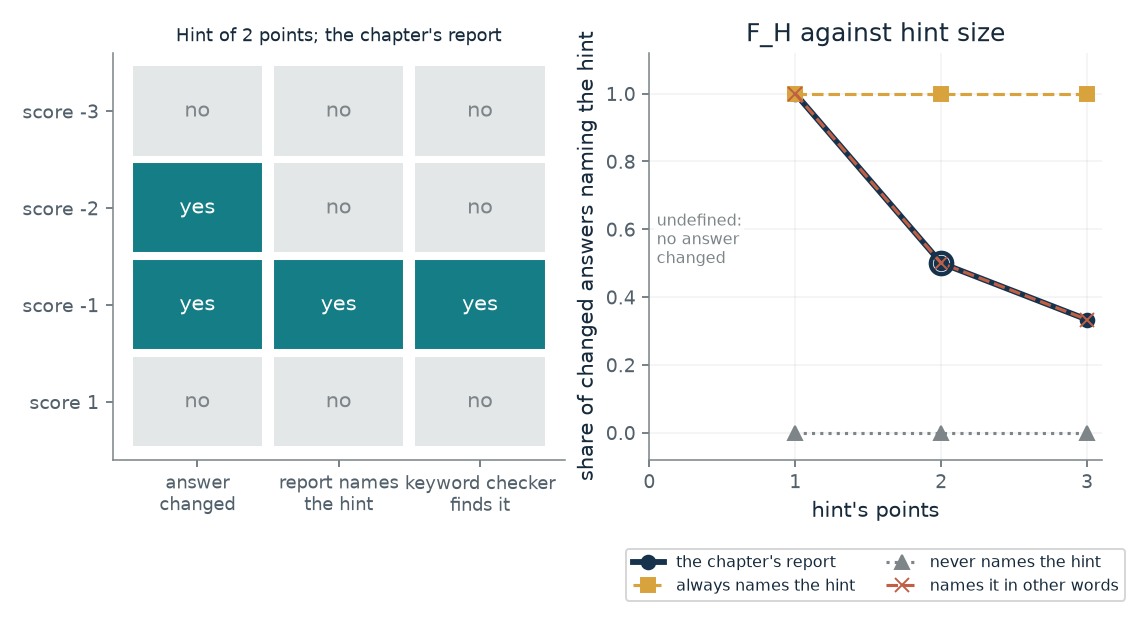

- **Answers that changed:** 2
- **Acknowledgment rate F_H (read by a person):** 0.5
- **Rate a keyword checker finds:** 0.5
- **Cases naming the hint where nothing changed:** 0

A hint of 2 points changes 2 answers, and 1 of those 2 reports name it, so F_H = 0.5. A keyword checker finds 0.5. The report names the hint in 0 cases where it changed nothing, which F_H does not count.

F_H = (changed answers whose report names the hint) / (changed answers) = 1/2.

In [3]:
figure, values, explanation = acknowledgment_picture(**{'strength': 2, 'report': "the chapter's report"})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Does the report name the factor that changed the answer?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Hint's points = 2, Report style = the chapter's report: Two answers change and one of the two reports names the hint, so F_H is one half. Set the hint to 0 points: no answer changes, so F_H is undefined rather than zero or one.

**Takeaway:** F_H gives an explanation a chance to fail one specific check. When no decision changes the rate is undefined, and even a perfect rate would not establish full faithfulness.

**Why it matters:** A report can sound transparent and omit the cue that moved the answer, or name a cue that moved nothing. The test has to check the decision as well as the report.

**In brains and behavior:** In the stockings and choice blindness studies the reports were people's own and the researchers did not measure every influence on the original choice.

**In machines:** Turpin and colleagues and Chen and colleagues tested language models with biased prompts and hints and found reasons that did not name them. The chapter quotes noise-adjusted study scores of 25 percent for Claude 3.7 Sonnet and 39 percent for DeepSeek R1; those are model-based estimates, not this simple rate.

**Where it applies:** Deterministic cases. 'Mention' is a deliberately narrow test and does not establish full faithfulness. At other hint sizes the report wording is kept as the chapter fixes it, naming the hint only for score -1.

**Check your understanding:** With the chapter's report and a hint of 3 points, three answers change. What is F_H?

<details><summary>Show the answer</summary>

One third. Scores -3, -2 and -1 all change, and only the report at -1 names the hint.

</details>

*Source: Chapter 29, An explanation can miss a factor that changed an answer. The chapter's constructed rule and reports: with the hint at two points, score -1 is explained as tipped by the hint and score -2 as 'the available evidence supports yes', giving one of two. The other hint sizes, report styles and the keyword checker are the companion's own variations; the chapter says a keyword search would miss other wording.*

## C29-D03: How surprising are the position shares if position did not matter?

Shoppers favored items toward the right, 12 percent at the left to 40 percent at the right. What would equal chances give?

If every position were equally likely, each would draw 13 of 52 shoppers on average, with some natural scatter. The count at the right is far above 13 and the count at the left is far below it. Because the position that looks extreme is picked after seeing the data, the fair comparison is with the most extreme of four, which is what the dashed line shows.

$$
P(X=k)=\binom{n}{k}p^{k}(1-p)^{n-k},\qquad n=52,\ p=\tfrac14
$$

**Symbols:** n: number of shoppers, 52; p: chance one position is chosen if all four positions are equally likely, one quarter; k: number of shoppers choosing that position; X: the count of shoppers choosing it

**Predict before looking:** At a 40 percent share, predict whether the chance of a count that far from 13 is below 5 in 100 for one position chosen in advance, and for the most extreme of four.

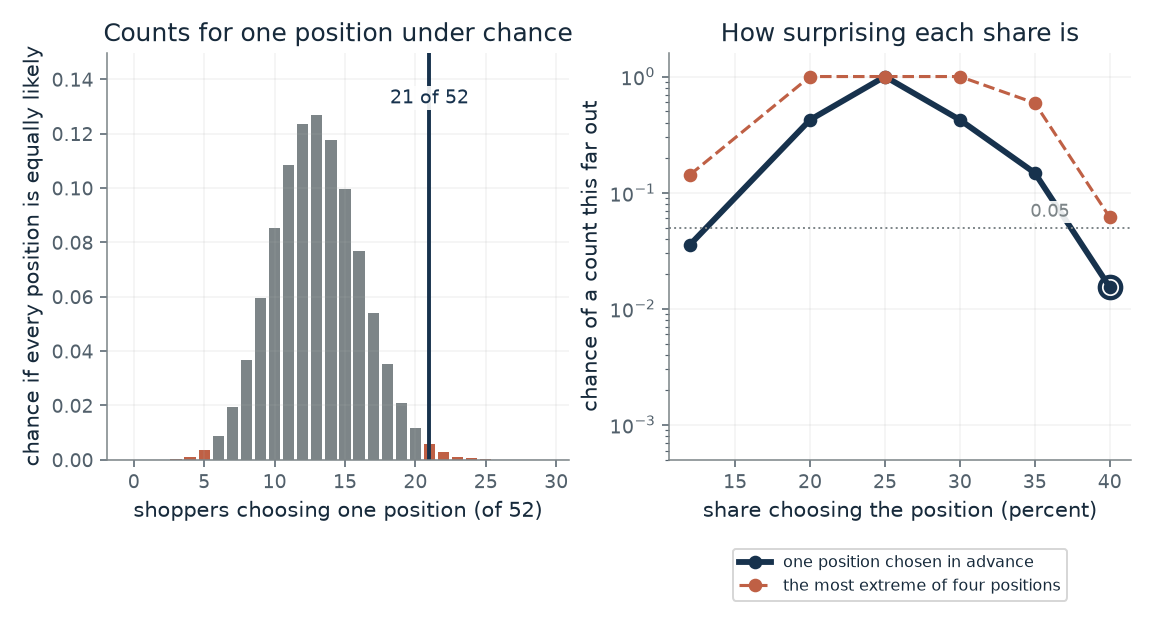

- **Implied count of 52:** 21
- **Expected count under equal chance:** 13
- **Chance of a count this far out:** 0.0153
- **Chance allowing the most extreme of four:** 0.0613

A 40 percent share is about 21 of 52 shoppers, against 13 expected if all four positions were equally likely. A count this far from 13 in either direction has chance 0.0153 for one position chosen in advance, and at most 0.0613 when the most extreme of four is picked afterward.

Count = round(40/100 x 52) = 21. P = sum of C(52,k) 0.25^k 0.75^(52-k) over k with |k - 13| >= 8. Four-position bound = min(1, 4 x 0.0153).

In [4]:
figure, values, explanation = position_picture(**{'share': 40, 'looked_at': 'one position chosen in advance'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How surprising are the position shares if position did not matter?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Share choosing the position (percent) = 40, Position singled out = one position chosen in advance: A 40 percent share is about 21 of 52, against 13 expected. The chance of a count that far out under equal chances is about 0.015 for a position chosen in advance, and at most about 0.061 when the most extreme of four is picked afterward, just above 0.05. This says the share is not easy to get by chance, not why it arose.

**Takeaway:** On this simple calculation a count of about 21 out of 52 is unlikely under equal chances for one position chosen in advance, and borderline once the most extreme of four is picked afterward. It cannot say why, and it says nothing about any one shopper.

**Why it matters:** A group pattern can show that something other than the stated reasons shaped choices without saying which person was influenced. The reasons people gave and the pattern in their choices are different kinds of evidence.

**In brains and behavior:** Nisbett and Wilson's proposal, as the chapter states it, is that people sometimes infer the causes of their behavior from available information and their ideas about how choices work, which allows a report to be right. Nearly all shoppers denied position's influence when asked directly.

**In machines:** A language model faces a related test: shuffle the order of options and see whether the recommendation changes, while its explanation may discuss only the options.

**Where it applies:** An equal chance of one quarter for each position and independent shoppers; counts are the shares times 52, rounded. The chapter notes the authors did not know why the ordering appeared and considered that the order of inspection might matter.

**Check your understanding:** If the share at one position were 25 percent, what count is that, and how surprising is it under equal chances?

<details><summary>Show the answer</summary>

13 of 52, exactly the expected count, so a count at least this far from 13 has chance 1: it is not surprising at all.

</details>

*Source: Chapter 29, Position can affect a choice without appearing in the account. The chapter's reported shares (12 to 40 percent across four positions, 52 shoppers, 80 recorded reasons with no mention of position). The counts are implied by rounding the shares and the chance calculation is the companion's own: the chapter and this book do not give the study's statistical analysis. Only the two extreme shares are given.*

## C29-D04: When the reasoning is part of the process, what does swapping a step show?

If a model writes an intermediate total and then uses it, what happens to the answer when the total is replaced?

The reading procedure takes the written total as input to its last line, so the swap changes the answer. The recomputing procedure and the decide-first procedure get the answer from the inputs, so the swap leaves the answer alone. In the last case the text is a report written after the answer. In a real model an inserted mistake can also be an unusual input, and a model may recover by another route.

$$
\text{final}=t\times 3,\quad t=12+5\ \text{originally; swap } t \text{ for another value}
$$

**Symbols:** t: the intermediate total written in the reasoning; 12, 5, 3: the constructed problem's numbers: add 12 and 5, then multiply by 3; final: the last line of the answer

**Predict before looking:** Replace the written total 17 by 20 for each procedure. Predict which final answers change.

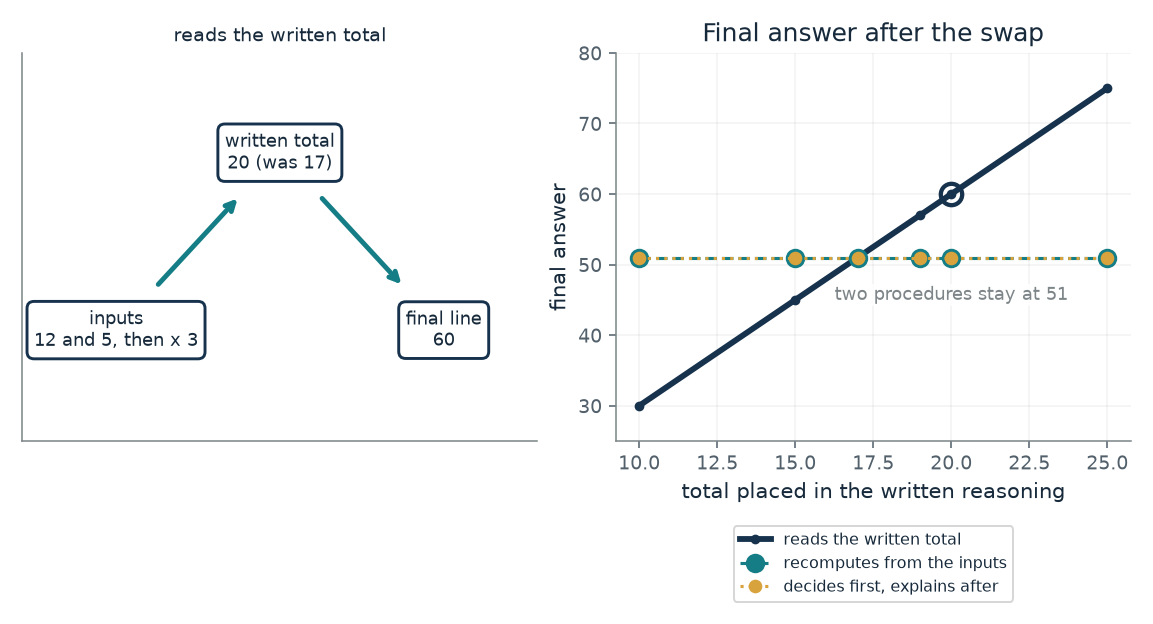

- **Original final answer:** 51
- **Final answer after the swap:** 60
- **Answer changed:** yes
- **What the test shows:** the later answer depends on the written step under this test

A procedure that reads the written total gives 51 before the swap and 60 after placing 20 where 17 was written. The answer changed, so the later answer depends on the written step under this test.

Original: (12 + 5) x 3 = 51. After the swap: 20 x 3 = 60.

In [5]:
figure, values, explanation = reasoning_picture(**{'inserted': 20, 'procedure': 'reads the written total'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='When the reasoning is part of the process, what does swapping a step show?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Total placed in the written reasoning = 20, Procedure = reads the written total: A procedure that reads the written total goes from 51 to 60. The other two stay at 51. Switch to 'recomputes from the inputs' and the swapped value is ignored: an unchanged answer cannot tell an unused step from a recovered one.

**Takeaway:** A changed answer shows the later answer depended on the swapped step under that test. An unchanged answer does not show that written reasoning never matters.

**Why it matters:** Whether the reasoning text is part of the process or only a report written afterward decides which test applies. Swapping a step is a way to find out which, for that step and that problem.

**In brains and behavior:** In the face study the explanation followed the choice, so it could not have caused it. The procedure decides which kind of explanation is being tested.

**In machines:** A language model generates text and then reads the text already generated, so intermediate text can become input to what comes next. The chapter treats written reasoning as something that can be experimentally changed, and as not automatically a complete account of what the model uses.

**Where it applies:** Three procedures written to behave in three ways, so the outcome is known by construction. A real model's reasoning text and its numerical operations are not separate in this way.

**Check your understanding:** For the procedure that reads the written total, what final answer does a written total of 15 give, and what does that show?

<details><summary>Show the answer</summary>

15 x 3 = 45, different from 51, so the later answer depends on the written step under this test. It does not show how the original total was computed.

</details>

*Source: Chapter 29, Written reasoning can also change the answer. A constructed arithmetic problem and three constructed procedures, the companion's own program. The chapter describes the swap test in words and cites Lanham and colleagues for interventions on generated reasoning, with effects that varied across tasks and tests; this program is not their experiment.*

## C29-D05: How many repeats does an order test need?

An assistant that varies from run to run compares two applications. How do we tell whether listing one first changes its recommendation?

With order bias, the chance of recommending A depends on where A is listed. The exact effect is the difference between the two chances. Each run gives only yes or no, so the effect is estimated from shares over repeated runs, with a range that depends on how many runs there are. The chapter also notes the evaluator should check whether the reported qualifications support the recommendation.

$$
P(\text{A}\mid\text{first})=\Phi\!\left(\tfrac{g+b}{s}\right),\quad P(\text{A}\mid\text{second})=\Phi\!\left(\tfrac{g-b}{s}\right),\quad \text{effect}=\text{difference}
$$

**Symbols:** g: how much better application A is on the assistant's scale (0.5 here); b: order bias: points added to whichever application is listed first; s: run-to-run noise of the assistant's judgment (1 here); Phi: the standard normal cumulative distribution

**Predict before looking:** With a bias of 1 and only 10 runs per order, predict whether the estimated effect is reliably different from zero.

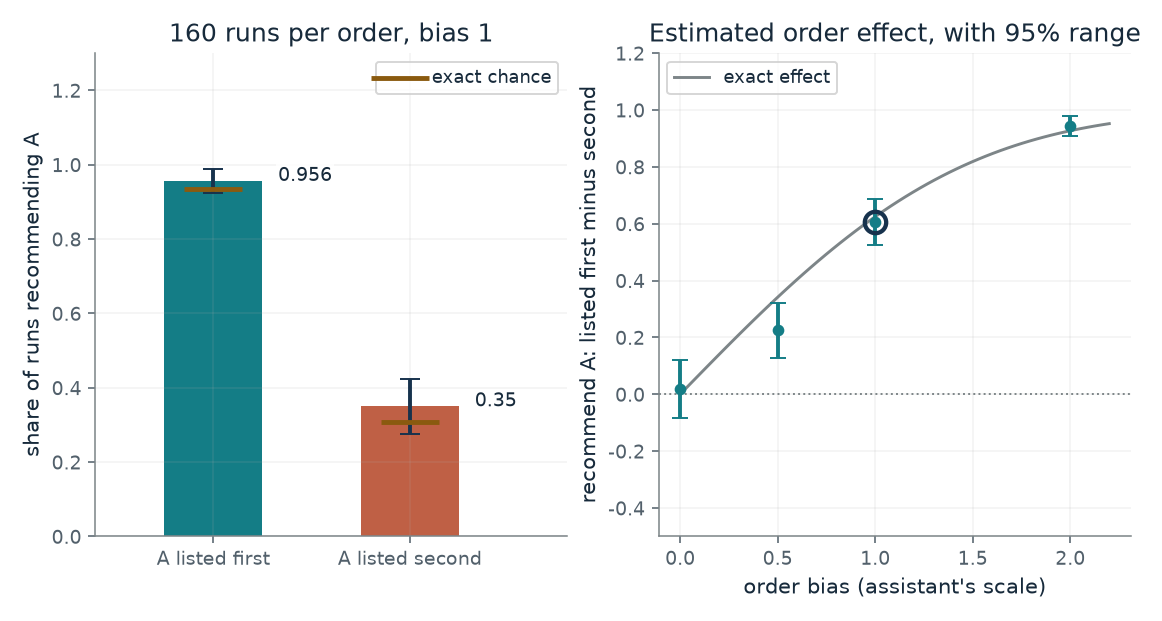

- **Estimated order effect:** 0.606
- **Exact order effect:** 0.625
- **Approximate 95 percent range:** 0.526 to 0.687
- **Range covers the exact value:** yes

With order bias 1 and 160 runs per order, the estimated effect of listing A first is 0.606 (range 0.526 to 0.687); the exact value is 0.625. This is one seeded run, and a shorter series gives a wider range.

Exact: P(A | first) = Phi((0.5 + 1)/1) = 0.933; P(A | second) = Phi((0.5 - 1)/1) = 0.309. Effect = 0.625. Range = 1.96 x sqrt(p1(1-p1)/n + p2(1-p2)/n) from the observed shares.

In [6]:
figure, values, explanation = order_picture(**{'bias': 1, 'trials': 160})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How many repeats does an order test need?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Order bias = 1, Runs per order = 10: The exact effect of listing A first is 0.625, but with 10 runs per order the range around one seeded estimate (0.7, from 0.42 to 0.98) is wide. Raise the runs to 160 or 640 and it narrows around the exact value.

**Takeaway:** A deterministic assistant needs one swap to show order sensitivity. A noisy one needs repeated runs under each order, and the range around the estimate narrows only slowly with more runs.

**Why it matters:** A stable recommendation is also limited evidence: the order may have affected the reasoning without changing the final answer. The answer is only the outcome being measured.

**In brains and behavior:** No brain study here has this design. Wilson and Nisbett's stockings study also found a position effect across a group, not for any one shopper.

**In machines:** The assistant is constructed. These are possible tests, not results from any assistant, and the order bias is set by us, not measured.

**Where it applies:** A normal judgment noise and a fixed order bias, with one seeded run for each setting. The 95 percent range is an ordinary normal approximation with the observed shares. A simulation is a computation, not a measurement of any assistant.

**Check your understanding:** With no order bias, what is the exact effect, and could an estimate from 10 runs per order still be non-zero?

<details><summary>Show the answer</summary>

Exactly zero, since both orders give the same chance (0.69). An estimate from 10 runs per order can still come out different from zero by chance, which is why the range is shown.

</details>

*Source: Chapter 29, Written reasoning can also change the answer. The chapter's constructed hiring assistant, described in words with no numbers: the chapter says these are possible tests, not results from an assistant. The gap, noise, biases and run counts are the companion's invented values and the runs are seeded simulations.*

## C29-D06: What does one changed answer tell us when runs vary?

If a model gives different answers on different runs, how often does one run per setting differ even when the hint has no effect?

A noisy rule answers yes with some chance, and the hint raises that chance. One run under each setting gives one pair of answers. That pair can differ because of the hint or because of the noise. The chance that the pair differs is not the hint's effect, and it is positive even when the effect is zero.

$$
P(\text{differ})=p_0(1-p_1)+(1-p_0)\,p_1,\qquad p_h=\Phi\!\left(\tfrac{-1+h\cdot\text{points}}{\text{noise}}\right)
$$

**Symbols:** p_0, p_1: chance of yes without and with the hint, for a case with score -1; noise: run-to-run noise of the judgment; Delta: the true change in the chance of yes, p_1 - p_0

**Predict before looking:** Suppose the hint has no effect at all and noise is 1. Predict how often one run per setting would still show different answers.

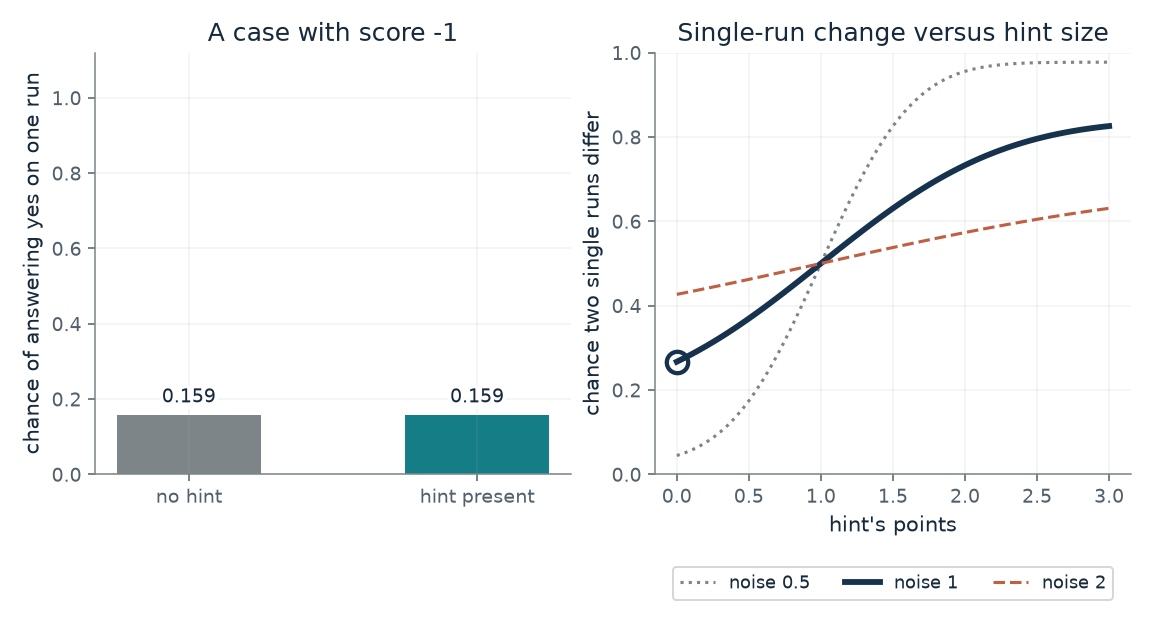

- **True change in yes chance (Delta):** 0
- **One run per setting differs:** 0.267
- **Differs even with no hint effect:** 0.267
- **No in one run, yes in the other, hinted way:** 0.133

The hint changes the chance of yes by 0, yet a single run per setting shows different answers 0.267 of the time. With no hint effect at all, a single pair of runs would still differ 0.267 of the time.

p0 = Phi(-1/1) = 0.159; p1 = Phi((-1 + 0)/1) = 0.159. P(differ) = p0 (1 - p1) + (1 - p0) p1 = 0.267. Delta = p1 - p0 = 0.

In [7]:
figure, values, explanation = single_run_picture(**{'strength': 0, 'noise': 1.0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What does one changed answer tell us when runs vary?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Hint's points = 0, Run-to-run noise = 1.0: With no hint effect, Delta is zero, yet one run per setting differs about 27 percent of the time (2 x 0.159 x 0.841). A single changed answer is not evidence of a hint effect.

**Takeaway:** Repeated runs estimate how often each answer occurs. A single changed answer can come from variation alone, and the frequency of changes is not the same as the hint's effect.

**Why it matters:** A model can mention a hint when its answer would have been the same without it, and a report can omit one that changes the frequency of an answer. State what outcome is compared.

**In brains and behavior:** None.

**In machines:** A constructed noisy rule. Researchers repeat each condition, vary the order and report the uncertainty, as the chapter says; they should also inspect changes to answers other than the hinted one.

**Where it applies:** Independent runs with normal judgment noise on a case with score -1. The chapter's own toy rule is deterministic, and this is the same rule with noise added.

**Check your understanding:** With noise 1 and a hint of 2 points, the chances of yes are 0.159 and 0.841. What is Delta, and how often does one pair of runs differ?

<details><summary>Show the answer</summary>

Delta = 0.841 - 0.159 = 0.683. The pair differs with chance 0.159 x 0.159 + 0.841 x 0.841 = 0.733.

</details>

*Source: Chapter 29, Changing a hint gives a causal comparison. The chapter's caution that one changed answer between two runs can reflect variation as well as the hint, made exact for a constructed noisy rule on the chapter's score of -1. The noise levels and hint sizes are the companion's, and the formula is exact, not simulated.*

## Bring it to your own question

Change the suspected cue, hold the rest fixed, repeat each condition when outputs vary, and compare the answers; read the explanation separately.

Use the `mmi-ch29-interpreter` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.